# Schwarzchild orbit-superposition modelling

My personal notes following the Agama example. 

In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
%matplotlib inline
plt.rc('figure', dpi=100)
plt.rc('font', size=10)
plt.rc('axes', linewidth=0.5)
plt.rc('mathtext', fontset='stix')

In [2]:
q = 0.6
total_mass = 1.0 
bh_mass = 0.1 
pot_stars = agama.Potential(type="spheroid", gamma=1, beta=5, mass=total_mass, scaleRadius=1,axisRatioZ=q)
dens_stars = pot_stars # reassignment? why? 
pot_bh = agama.Potential(type="Plummer",mass=bh_mass,scaleRadius=0) # interesting!, zero?
pot_total = pot_stars + pot_bh # pot_total = agama.Potential(pot_stars, pot_bh). cool how he changed the internal functions!

### Creating orbital initial conditions 

The default method for sampling takes positions from the density profile and gives velocities through performing the eddington inversion with poisson's equation. It uses the spericalized density and potential pair. Not sure on the details. But, the important part is that this proper samples the types of orbits. Uniformly sampling the density profile is a good way to do this but certainly isn't the best. There's a work by Neureiter et al. 2021 who studied this further to come up with a more optimal sampling. Or, they did a bigger project and good sampling is part of it. 

In [3]:
num_orbits = int(2e3)
ic, mass = dens_stars.sample(num_orbits,potential = pot_total)

### Detour. 

Why not see what these orbits give? do they reproduce the density profile as a function of time? Why go through Schwartzchild modeling if I can already get a set of initial conditions?

In [4]:
integration_time = 1e2*pot_total.Tcirc(ic)
orbits=agama.orbit(
    potential=pot_total,
    ic=ic,
    time=integration_time,
    dtype=object)

2000 orbits complete (1112 orbits/s)


[Text(0.5, 0, 'x'), Text(0, 0.5, 'z'), None]

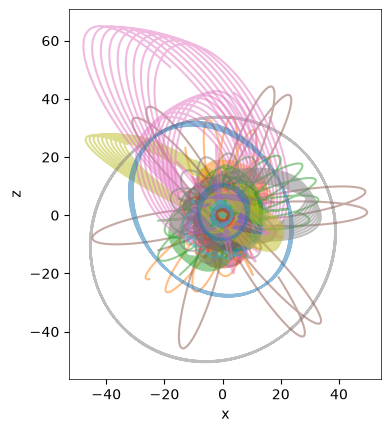

In [5]:
fig,axis=plt.subplots(1,1)
nsteps = int(1e4)
index_orbit = 15
for index_orbit in range(len(orbits)):
    tsteps = numpy.linspace(0,integration_time[index_orbit]/10,nsteps)
    axis.plot(orbits[index_orbit].x(tsteps),orbits[index_orbit].y(tsteps),alpha=.50)
axis.set(xlabel="x", ylabel="z",aspect="equal")

What is the density of such a model? how do I visualize the stellar density? 
Density in the merdional plane? 

[None, None, Text(0.5, 0, 'R')]

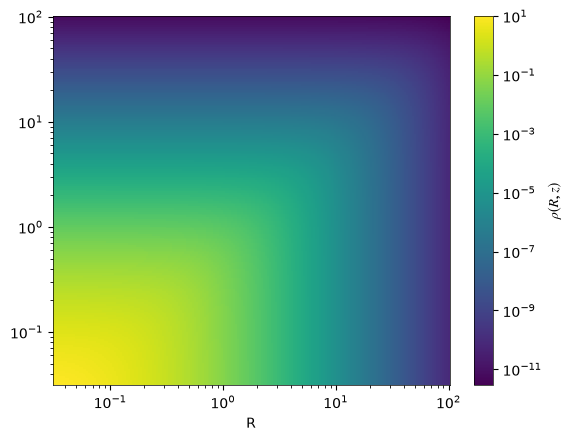

In [19]:
R = numpy.logspace(-1.5,2,200)
z = numpy.logspace(-1.5,2,200)
RR,ZZ = numpy.meshgrid(R,z)
xyz = numpy.column_stack((RR.ravel(),numpy.zeros_like(RR.ravel()),ZZ.ravel()))
rho_true = dens_stars.density(xyz).reshape(RR.shape)
fig,axis=plt.subplots(1,1)
m = axis.pcolormesh(R,z,rho_true,norm=matplotlib.colors.LogNorm(),shading="auto")
fig.colorbar(m,label=r"$\rho (R,z)$")
axis.set(xscale="log",yscale="log",xlabel="R")